# **Installation**

In [ ]:
!pip install chembl_webresource_client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.4/61.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.7/70.7 kB 4.4 MB/s eta 0:00:00


In [ ]:
from chembl_webresource_client.new_client import new_client
import pandas as pd

# **Preparation**

In [ ]:
# Look for target protein

target = new_client.target
target_query = target.search('mitogen activated protein kinase')
targets = pd.DataFrame.from_dict(target_query)

In [ ]:
targets

,cross_references,organism,pref_name,score,species_group_flag,target_chembl_id,target_components,target_type,tax_id
0,[],Mus musculus,MAP kinase p38,27.0,False,CHEMBL2111473,"[{'accession': 'P47811', 'component_descriptio...",PROTEIN FAMILY,10090.0
1,[],Homo sapiens,Mitogen-activated protein kinase 13,26.0,False,CHEMBL2939,"[{'accession': 'O15264', 'component_descriptio...",SINGLE PROTEIN,9606.0
2,[],Mus musculus,Mitogen-activated protein kinase 11,26.0,False,CHEMBL4335,"[{'accession': 'Q9WUI1', 'component_descriptio...",SINGLE PROTEIN,10090.0
3,[],Plasmodium falciparum,Putative uncharacterized protein pk7,26.0,False,CHEMBL6169,"[{'accession': 'O96214', 'component_descriptio...",SINGLE PROTEIN,5833.0
4,[],Homo sapiens,MAP kinase p38,26.0,False,CHEMBL2094115,"[{'accession': 'O15264', 'component_descriptio...",PROTEIN FAMILY,9606.0
...,...,...,...,...,...,...,...,...,...
9995,[],Homo sapiens,"Hydroxyacyl-coenzyme A dehydrogenase, mitochon...",0.0,False,CHEMBL6067363,"[{'accession': 'Q16836', 'component_descriptio...",SINGLE PROTEIN,9606.0
9996,[],Homo sapiens,Ethanolaminephosphotransferase 1,0.0,False,CHEMBL6067391,"[{'accession': 'Q9C0D9', 'component_descriptio...",SINGLE PROTEIN,9606.0
9997,[],Burkholderia pseudomallei (strain K96243),Phosphoheptose isomerase,0.0,False,CHEMBL6067458,"[{'accession': 'Q93UJ2', 'component_descriptio...",SINGLE PROTEIN,272560.0
9998,[],Homo sapiens,Antigen peptide transporter 2,0.0,False,CHEMBL6067543,"[{'accession': 'Q03519', 'component_descriptio...",SINGLE PROTEIN,9606.0


In [ ]:
#Choosing single protein as target

filtered_targets = targets[
    (targets['target_type'] == 'SINGLE PROTEIN') &
    (targets['pref_name'] == 'Mitogen-activated protein kinase 1') &
    (targets['organism'] == 'Homo sapiens')
]
filtered_targets

,cross_references,organism,pref_name,score,species_group_flag,target_chembl_id,target_components,target_type,tax_id
27,[],Homo sapiens,Mitogen-activated protein kinase 1,23.0,False,CHEMBL4040,"[{'accession': 'P28482', 'component_descriptio...",SINGLE PROTEIN,9606.0


In [ ]:
# Select the target

protein_target = filtered_targets.target_chembl_id[27]
protein_target

'CHEMBL4040'

In [ ]:
# Bioactivity data retrieval from CHEMBL3471, represented by IC50 value

compounds = new_client.activity
compounds_query = compounds.filter(target_chembl_id = protein_target).filter(standard_type = 'IC50')
compounds_df = pd.DataFrame.from_dict(compounds_query)
compounds_df.head()

,action_type,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,Not Determined,309589,[],CHEMBL732073,Inhibition of Mitogen-activated protein kinase...,B,None,None,BAO_0000190,...,Homo sapiens,Mitogen-activated protein kinase 1,9606,None,None,IC50,nM,UO_0000065,None,None
1,None,Not Determined,312219,[],CHEMBL732073,Inhibition of Mitogen-activated protein kinase...,B,None,None,BAO_0000190,...,Homo sapiens,Mitogen-activated protein kinase 1,9606,None,None,IC50,nM,UO_0000065,None,None
2,None,None,315773,[],CHEMBL729502,Inhibition of Mitogen-activated protein kinase...,B,None,None,BAO_0000190,...,Homo sapiens,Mitogen-activated protein kinase 1,9606,None,None,IC50,nM,UO_0000065,None,2500.0
3,None,None,315778,[],CHEMBL729502,Inhibition of Mitogen-activated protein kinase...,B,None,None,BAO_0000190,...,Homo sapiens,Mitogen-activated protein kinase 1,9606,None,None,IC50,nM,UO_0000065,None,2800.0
4,None,None,317028,[],CHEMBL729502,Inhibition of Mitogen-activated protein kinase...,B,None,None,BAO_0000190,...,Homo sapiens,Mitogen-activated protein kinase 1,9606,None,None,IC50,nM,UO_0000065,None,2.5


In [ ]:
compounds_df.shape

(9054, 46)

In [ ]:
# Handling missing data
print('Std value')
print(compounds_df['standard_value'].isna().sum())
print('\nCanon SMILES')
print(compounds_df['canonical_smiles'].isna().sum())

Std value
873

Canon SMILES
37


In [ ]:
# Dropping row that has missing standard_value and canonical SMILES

compounds_df = compounds_df.dropna(subset=['standard_value', 'canonical_smiles']).reset_index(drop=True)
compounds_df.shape

(8178, 46)

In [ ]:
# Compound's activity determination based on IC50 value

compounds_class= []
for i in compounds_df['standard_value']:
  if float(i) >= 10000:
    compounds_class.append('inactive')
  elif float(i) <= 1000:
    compounds_class.append('active')
  else:
    compounds_class.append('intermediate')

In [ ]:
# Creating new df

selected_df = pd.concat([compounds_df['molecule_chembl_id'], compounds_df['canonical_smiles'], compounds_df['standard_value'], pd.Series(compounds_class, name = 'bioactivity_class').to_frame()], axis = 1)
selected_df

,molecule_chembl_id,canonical_smiles,standard_value,bioactivity_class
0,CHEMBL397591,Nc1ncc(/C=C/CNC(=O)c2cc(Br)c(Br)[nH]2)[nH]1,2500.0,intermediate
1,CHEMBL35482,COc1cccc(-c2cc(=O)c3ccccc3o2)c1N,2800.0,intermediate
2,CHEMBL388978,CN[C@@H]1C[C@H]2O[C@@](C)([C@@H]1OC)n1c3ccccc3...,2.5,active
3,CHEMBL356164,NC(=O)c1cc(Br)c(Br)[nH]1,2500.0,intermediate
4,CHEMBL361708,NC1=NC(=O)/C(=C2\CCNC(=O)c3[nH]c(Br)cc32)N1,9.0,active
...,...,...,...,...
8173,CHEMBL6039685,Cn1nccc1Nc1cc(-c2cc(F)c3c(c2)CCN3C(=O)Cc2cccnc...,550.0,active
8174,CHEMBL5973018,COCC1Cc2cc(-c3ccnc(Nc4ccnn4C)c3)cc(F)c2N1C(=O)...,10.0,active
8175,CHEMBL5752603,CC1CN(C(=O)Cc2cccnc2Cl)c2c(F)cc(-c3ccnc(Nc4ccn...,4.8,active
8176,CHEMBL5950743,Cn1nccc1Nc1cc(-c2cc(F)c3c(c2)CCN3C(=O)C(O)c2cc...,10.0,active


In [ ]:
# Saving the edited dataset

selected_df.to_csv('MAPK1_Human.csv', index=False)

# **EDA**

In [ ]:
import pandas as pd

selected_df = pd.read_csv('MAPK1_Human.csv')
selected_df

,molecule_chembl_id,canonical_smiles,standard_value,bioactivity_class
0,CHEMBL397591,Nc1ncc(/C=C/CNC(=O)c2cc(Br)c(Br)[nH]2)[nH]1,2500.0,intermediate
1,CHEMBL35482,COc1cccc(-c2cc(=O)c3ccccc3o2)c1N,2800.0,intermediate
2,CHEMBL388978,CN[C@@H]1C[C@H]2O[C@@](C)([C@@H]1OC)n1c3ccccc3...,2.5,active
3,CHEMBL356164,NC(=O)c1cc(Br)c(Br)[nH]1,2500.0,intermediate
4,CHEMBL361708,NC1=NC(=O)/C(=C2\CCNC(=O)c3[nH]c(Br)cc32)N1,9.0,active
...,...,...,...,...
8176,CHEMBL6039685,Cn1nccc1Nc1cc(-c2cc(F)c3c(c2)CCN3C(=O)Cc2cccnc...,550.0,active
8177,CHEMBL5973018,COCC1Cc2cc(-c3ccnc(Nc4ccnn4C)c3)cc(F)c2N1C(=O)...,10.0,active
8178,CHEMBL5752603,CC1CN(C(=O)Cc2cccnc2Cl)c2c(F)cc(-c3ccnc(Nc4ccn...,4.8,active
8179,CHEMBL5950743,Cn1nccc1Nc1cc(-c2cc(F)c3c(c2)CCN3C(=O)C(O)c2cc...,10.0,active


In [ ]:
# Count the frequency of each bioactivity class
bioactivity_counts = selected_df['bioactivity_class'].value_counts()

print("Bioactivity Class Counts:")
print(bioactivity_counts)

Bioactivity Class Counts:
bioactivity_class
active          7355
inactive         510
intermediate     316
Name: count, dtype: int64


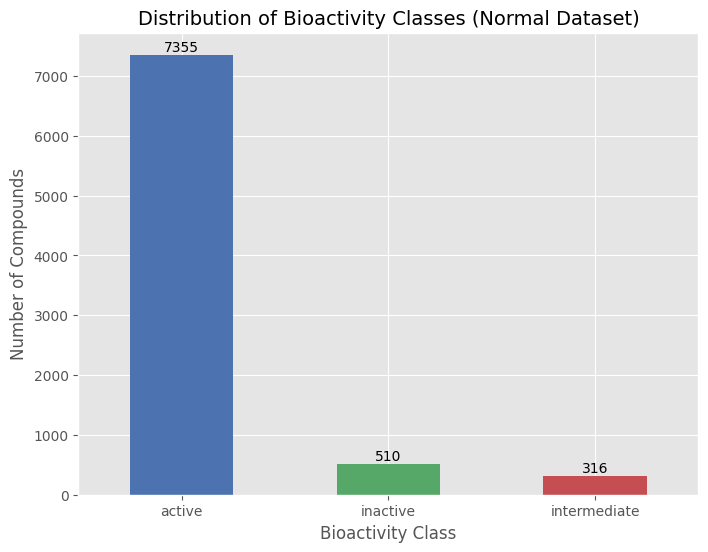

In [ ]:
import matplotlib.pyplot as plt

# Calculate the counts
bioactivity_counts = selected_df['bioactivity_class'].value_counts()

# Set the style for better visualization (optional)
plt.style.use('ggplot')

# Create the plot
plt.figure(figsize=(8, 6))

# Define colors for better clarity (e.g., matching the order in value_counts)
class_order = bioactivity_counts.index.tolist()
color_map = {'active': '#4c72b0', 'inactive': '#55a868', 'intermediate': '#c44e52'}
plot_colors = [color_map.get(c, 'gray') for c in class_order]

# Plot the calculated counts
bioactivity_counts.plot(kind='bar', color=plot_colors)

# Add labels and title
plt.title('Distribution of Bioactivity Classes (Normal Dataset)', fontsize=14)
plt.xlabel('Bioactivity Class', fontsize=12)
plt.ylabel('Number of Compounds', fontsize=12)

# Rotate x-axis labels for better visibility
plt.xticks(rotation=0)

# Add the counts on top of the bars
for i, count in enumerate(bioactivity_counts):
    # Adjusting vertical position (count + 10) for better spacing
    plt.text(i, count + 10, str(count), ha='center', va='bottom', fontsize=10)

**Highly imbalance class, so we have to undersampling the major class (active one)**

In [ ]:
from sklearn.utils import resample
import numpy as np

# Separate Majority and Minority Classes
df_majority = selected_df[selected_df['bioactivity_class'] == 'active']
df_minority_inactive = selected_df[selected_df['bioactivity_class'] == 'inactive']
df_minority_intermediate = selected_df[selected_df['bioactivity_class'] == 'intermediate']

# Define Target Sample Size using the size of the largest minority class (510) as the target
target_size = len(df_minority_inactive)

# Undersample the Majority Class
df_majority_undersampled = resample(df_majority,
                                   replace=False,          # Set to False for undersampling
                                   n_samples=target_size,  # Reduce the size
                                   random_state=42)        # Set seed for reproducibility

# Combine the Undersampled Data with Minority Classes
balanced_df = pd.concat([df_majority_undersampled,
                         df_minority_inactive,
                         df_minority_intermediate])

print("\n--- Balanced Distribution ---")
print(balanced_df['bioactivity_class'].value_counts().sort_index())

print(f"\nNew total dataset size: {len(balanced_df)}")


--- Balanced Distribution ---
bioactivity_class
active          510
inactive        510
intermediate    316
Name: count, dtype: int64

New total dataset size: 1336


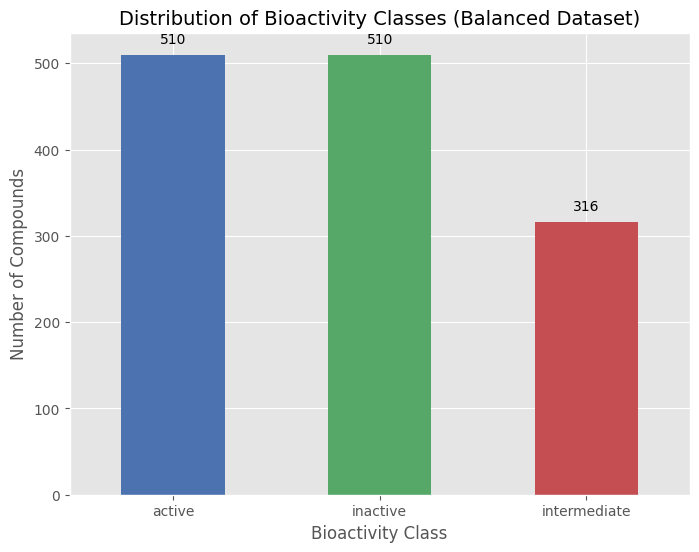

In [ ]:
# Calculate the counts
bioactivity_counts = balanced_df['bioactivity_class'].value_counts()

# Set the style for better visualization (optional)
plt.style.use('ggplot')

# Create the plot
plt.figure(figsize=(8, 6))

# Define colors for better clarity (e.g., matching the order in value_counts)
class_order = bioactivity_counts.index.tolist()
color_map = {'active': '#4c72b0', 'inactive': '#55a868', 'intermediate': '#c44e52'}
plot_colors = [color_map.get(c, 'gray') for c in class_order]

# Plot the calculated counts
bioactivity_counts.plot(kind='bar', color=plot_colors)

# Add labels and title
plt.title('Distribution of Bioactivity Classes (Balanced Dataset)', fontsize=14)
plt.xlabel('Bioactivity Class', fontsize=12)
plt.ylabel('Number of Compounds', fontsize=12)

# Rotate x-axis labels for better visibility
plt.xticks(rotation=0)

# Add the counts on top of the bars
for i, count in enumerate(bioactivity_counts):
    # Adjusting vertical position (count + 10) for better spacing
    plt.text(i, count + 10, str(count), ha='center', va='bottom', fontsize=10)

**Compare the descriptive statistics before and after undersampling was performed**

In [ ]:
print('Before undersampling')
# Filter the original DataFrame for 'active' class
print(selected_df[selected_df['bioactivity_class'] == 'active']['standard_value'].describe())

print('\nAfter undersampling')
# Filter the balanced DataFrame for 'active' class
print(balanced_df[balanced_df['bioactivity_class'] == 'active']['standard_value'].describe())

Before undersampling
count    7355.000000
mean       72.307389
std       158.823406
min         0.004310
25%         2.100000
50%        10.000000
75%        50.000000
max      1000.000000
Name: standard_value, dtype: float64

After undersampling
count     510.000000
mean       69.228099
std       153.671919
min         0.008370
25%         2.300000
50%         9.000000
75%        50.000000
max      1000.000000
Name: standard_value, dtype: float64


**Normalize the IC50 Data to pIC50**

In [ ]:
import numpy as np

def pIC50(input):
    pIC50 = []

    for i in input['standard_value_norm']:
        molar = i*(10**-9) # Converts nM to M
        pIC50.append(-np.log10(molar))

    input['pIC50'] = pIC50
    x = input.drop('standard_value_norm', axis=1)

    return x

In [ ]:
# IC50 Dataset Overview
balanced_df.standard_value.describe()

,standard_value
count,1336.000000
mean,17322.102792
std,43084.050168
min,0.008370
25%,39.930000
50%,2500.000000
75%,12000.000000
max,850000.000000


In [ ]:
def norm_value(input):
    norm = []

    for i in input['standard_value']:
        if i > 100000000:
          i = 100000000
        norm.append(i)

    input['standard_value_norm'] = norm
    x = input.drop('standard_value', axis=1)

    return x

In [ ]:
df_norm = norm_value(balanced_df)
df_norm

,molecule_chembl_id,canonical_smiles,bioactivity_class,standard_value_norm
5208,CHEMBL6012475,CN1C[C@@H](Cc2ccc(Cl)c(F)c2)c2nnc3cc(-c4ccnc(N...,active,0.6
7814,CHEMBL4869800,COc1cc(F)cc([C@@H](CO)NC(=O)[C@@H](C)N2Cc3ccc(...,active,2.0
3806,CHEMBL5082830,O=C1N([C@H](CO)c2cccc(Cl)c2)Cc2cc(-c3nc(NC4CCO...,active,5.8
7651,CHEMBL5796169,C[C@@H](NC(=O)CN1Cc2ccc(-c3nc(NC4CCOCC4)ncc3Cl...,active,2.4
2350,CHEMBL3975320,CC1CC(Oc2n[nH]c3cc(NC(=O)N[C@@H](c4ccccc4)C(C)...,active,1.0
...,...,...,...,...
8124,CHEMBL5917662,Cc1ccc2[nH]nc(-c3ccc(F)c(CO)c3)c2c1,intermediate,4000.0
8125,CHEMBL5876616,Cc1ccc2[nH]nc(-c3ccc4c(c3)OCO4)c2c1,intermediate,6600.0
8126,CHEMBL5801861,Cc1ccc2[nH]nc(-c3ccc(O)cc3)c2c1,intermediate,7700.0
8127,CHEMBL5770842,Cc1ccc2[nH]nc(-c3ccc(C(N)=O)cc3)c2c1,intermediate,3900.0


In [ ]:
df_norm.standard_value_norm.describe()

,standard_value_norm
count,1336.000000
mean,17322.102792
std,43084.050168
min,0.008370
25%,39.930000
50%,2500.000000
75%,12000.000000
max,850000.000000


In [ ]:
df_pIC50 = pIC50(df_norm)
df_pIC50

,molecule_chembl_id,canonical_smiles,bioactivity_class,pIC50
5208,CHEMBL6012475,CN1C[C@@H](Cc2ccc(Cl)c(F)c2)c2nnc3cc(-c4ccnc(N...,active,9.221849
7814,CHEMBL4869800,COc1cc(F)cc([C@@H](CO)NC(=O)[C@@H](C)N2Cc3ccc(...,active,8.698970
3806,CHEMBL5082830,O=C1N([C@H](CO)c2cccc(Cl)c2)Cc2cc(-c3nc(NC4CCO...,active,8.236572
7651,CHEMBL5796169,C[C@@H](NC(=O)CN1Cc2ccc(-c3nc(NC4CCOCC4)ncc3Cl...,active,8.619789
2350,CHEMBL3975320,CC1CC(Oc2n[nH]c3cc(NC(=O)N[C@@H](c4ccccc4)C(C)...,active,9.000000
...,...,...,...,...
8124,CHEMBL5917662,Cc1ccc2[nH]nc(-c3ccc(F)c(CO)c3)c2c1,intermediate,5.397940
8125,CHEMBL5876616,Cc1ccc2[nH]nc(-c3ccc4c(c3)OCO4)c2c1,intermediate,5.180456
8126,CHEMBL5801861,Cc1ccc2[nH]nc(-c3ccc(O)cc3)c2c1,intermediate,5.113509
8127,CHEMBL5770842,Cc1ccc2[nH]nc(-c3ccc(C(N)=O)cc3)c2c1,intermediate,5.408935


In [ ]:
df_pIC50.to_csv('bioactivity_data_3class_pIC50.csv', index=False)

**Box Plot of pIC50**

In [ ]:
import seaborn as sns
sns.set(style='ticks')
import matplotlib.pyplot as plt

/tmp/ipython-input-1174717308.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'bioactivity_class', y = 'pIC50', data = df_pIC50, palette='Set2')


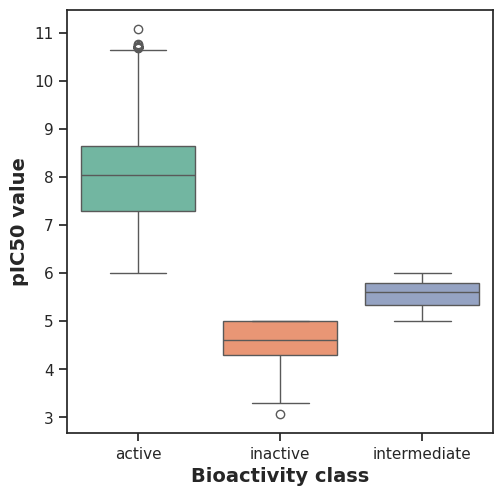

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'pIC50', data = df_pIC50, palette='Set2')

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('pIC50 value', fontsize=14, fontweight='bold')

plt.savefig('plot_ic50.png')